# Correction — Métriques de classification

Cette correction relie une confusion matrix aux métriques, compare trois seuils et mesure la variabilité de l'Average Precision par validation croisée. Le dataset intégré sert à apprendre le protocole et n'est pas un outil de diagnostic.

## Lire les rapports

Avec `TP=18`, `FP=7` et `FN=5`, la précision divise les vrais positifs par toutes les prédictions positives ; le rappel divise par les positifs réels. Le seuil modifie ces comptes. La cross-validation de la pipeline entière doit être faite sur la partie train : chaque fold réapprend imputation et standardisation sans voir son fold validation.

In [ ]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
tp, fp, fn = 18, 7, 5
precision = tp / (tp + fp); recall = tp / (tp + fn)
print('precision, recall, F1:', precision, recall, 2 * precision * recall / (precision + recall))
data = load_breast_cancer(as_frame=True); X, y = data.data, data.target
a, b, ya, yb = train_test_split(X, y, stratify=y, random_state=11)
model = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=2000)).fit(a, ya)
prob = model.predict_proba(b)[:, 1]
for threshold in [0.3, 0.5, 0.7]:
    pred = (prob >= threshold).astype(int)
    print(threshold, precision_score(yb, pred), recall_score(yb, pred), f1_score(yb, pred), confusion_matrix(yb, pred).tolist())
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=11)
scores = cross_val_score(model, a, ya, cv=cv, scoring='average_precision')
print('AP mean/std:', scores.mean().round(3), scores.std().round(3))


## Visualiser le compromis entre précision et rappel

Chaque point correspond à un seuil appliqué aux probabilités sur le même jeu illustratif. La figure décrit les conséquences des seuils ; le seuil d'une application doit être choisi sur validation selon un coût d'erreur défini, puis rapporté une fois sur test.

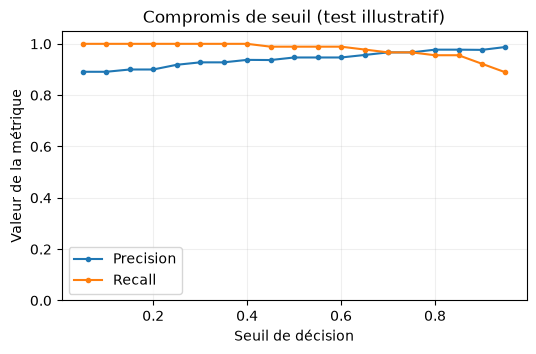

In [ ]:
import matplotlib.pyplot as plt
threshold_grid = np.linspace(0.05, 0.95, 19)
precision_values = []
recall_values = []
for current_threshold in threshold_grid:
    current_prediction = (prob >= current_threshold).astype(int)
    precision_values.append(precision_score(yb, current_prediction, zero_division=0))
    recall_values.append(recall_score(yb, current_prediction, zero_division=0))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(threshold_grid, precision_values, marker='o', markersize=3, label='Precision')
ax.plot(threshold_grid, recall_values, marker='o', markersize=3, label='Recall')
ax.set(xlabel='Seuil de décision', ylabel='Valeur de la métrique', title='Compromis de seuil (test illustratif)', ylim=(0, 1.05))
ax.legend(); ax.grid(alpha=0.2)
plt.show()

## Interprétation et limite

Les scores par fold exposent une partie de la variabilité due aux partitions, mais ils ne couvrent pas une éventuelle dérive de population. F1 ne contient pas explicitement les vrais négatifs ; Average Precision résume la courbe precision–recall et ne remplace pas une décision sur le seuil ou les coûts.